# 02_modelos: línea base y comparación de KNN, SVM, Random Forest y MLP
**Persona A.** Se evalúa **solo con validación cruzada estratificada sobre el entrenamiento** (submuestra de 25 000 registros generada en `01_eda`). El conjunto de prueba **no se carga** en este notebook: se usa una sola vez, en `04_modelo_final`.

## 0. Configuración

In [2]:
import sys, os, platform, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn
warnings.filterwarnings("ignore")

# --- AJUSTA ESTAS RUTAS ---
RUTA_TRAIN_SUB = "train_submuestra.csv"   # generado por 01_eda (partición oficial de ENTRENAMIENTO, sin duplicados)
RUTA_SRC       = "."                       # carpeta con preprocesamiento.py y modelos.py (en el repo: "../src")
DIR_REPORTES   = "reports"                 # en el repo: "../reports"

sys.path.insert(0, RUTA_SRC)
import preprocesamiento as pp
import modelos as mo

SEED = pp.SEED
np.random.seed(SEED)
os.makedirs(DIR_REPORTES, exist_ok=True)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("CPU núcleos:", os.cpu_count(), "| semilla:", SEED, "| pliegues:", mo.N_FOLDS)

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1
CPU núcleos: 2 | semilla: 42 | pliegues: 5


## 1. Datos de entrenamiento y Pipeline

In [3]:
train_sub = pd.read_csv(RUTA_TRAIN_SUB)
X, y, cat_ataque = pp.separar_xy(train_sub)      # quita id, attack_cat y label de los predictores
print("Entrenamiento:", X.shape, "| proporción de ataques:", y.mean().round(3))

# Variables: se excluye ct_ftp_cmd (idéntica a is_ftp_login, correlación 1.000)
num_cols, cat_cols = pp.columnas_por_tipo(X, excluir=pp.COLUMNAS_REDUNDANTES)
cols_log = pp.detectar_columnas_log(X, num_cols)   # solo con datos de entrenamiento
preprocesador = pp.construir_preprocesador(num_cols, cat_cols, cols_log)
modelos = mo.definir_modelos(preprocesador)
print(len(num_cols), "numéricas |", len(cat_cols), "categóricas |", len(cols_log), "con log1p")
print("Modelos:", list(modelos))

Entrenamiento: (25000, 42) | proporción de ataques: 0.488
38 numéricas | 3 categóricas | 30 con log1p
Modelos: ['Dummy (línea base)', 'KNN', 'SVM', 'Random Forest', 'MLP']


## 2. Validación cruzada estratificada (5 folds)
Cada pliegue ajusta el Pipeline completo con sus datos de entrenamiento y evalúa en el pliegue de validación, así que no hay fuga de información. El SVM es el más lento: puede tardar varios minutos en Colab.

In [4]:
resultados = {}
for nombre, pipe in modelos.items():
    t0 = time.perf_counter()
    resultados[nombre] = mo.evaluar_cv(pipe, X, y)
    r = resultados[nombre]["media"]
    print(f"{nombre:20s} F1={r['f1']:.4f}  Recall={r['recall']:.4f}  ROC-AUC={r['roc_auc']:.4f}  ({time.perf_counter()-t0:.0f} s en total)")

Dummy (línea base)   F1=0.0000  Recall=0.0000  ROC-AUC=0.5000  (1 s en total)
KNN                  F1=0.9045  Recall=0.9180  ROC-AUC=0.9654  (12 s en total)
SVM                  F1=0.9088  Recall=0.9747  ROC-AUC=0.9719  (79 s en total)
Random Forest        F1=0.9233  Recall=0.9441  ROC-AUC=0.9821  (42 s en total)
MLP                  F1=0.9116  Recall=0.9373  ROC-AUC=0.9765  (33 s en total)


## 3. Tabla única de resultados

In [5]:
tabla = mo.tabla_resultados(modelos, resultados)

# Versión legible: media ± desviación
leg = pd.DataFrame({"Modelo": tabla["Modelo"], "Hiperparámetros": tabla["Hiperparámetros"]})
for m in ["F1", "Precisión", "Recall", "ROC-AUC", "Exactitud"]:
    leg[m] = tabla[f"{m} (media)"].map("{:.4f}".format) + " ± " + tabla[f"{m} (desv)"].map("{:.4f}".format)
leg["Entrenamiento (s/pliegue)"] = tabla["Entrenamiento (s/pliegue)"].round(2)
leg["Inferencia (ms/1000 reg.)"] = tabla["Inferencia (ms/1000 reg.)"].round(1)

tabla.to_csv(f"{DIR_REPORTES}/tabla_resultados_cv.csv", index=False)       # valores numéricos
leg.to_csv(f"{DIR_REPORTES}/tabla_resultados_cv_legible.csv", index=False)  # para pegar en el informe
leg

,Modelo,Hiperparámetros,F1,Precisión,Recall,ROC-AUC,Exactitud,Entrenamiento (s/pliegue),Inferencia (ms/1000 reg.)
0,Dummy (línea base),strategy=most_frequent,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.5124 ± 0.0000,0.22,4.7
1,KNN,"n_neighbors=5, weights=uniform, p=2",0.9045 ± 0.0055,0.8914 ± 0.0062,0.9180 ± 0.0057,0.9654 ± 0.0036,0.9055 ± 0.0055,0.25,211.9
2,SVM,"kernel=rbf, C=1.0, gamma=scale",0.9088 ± 0.0054,0.8514 ± 0.0074,0.9747 ± 0.0033,0.9719 ± 0.0022,0.9046 ± 0.0060,10.91,470.4
3,Random Forest,"n_estimators=200, max_depth=None, min_samples_...",0.9233 ± 0.0046,0.9035 ± 0.0062,0.9441 ± 0.0048,0.9821 ± 0.0021,0.9236 ± 0.0047,8.04,32.3
4,MLP,"hidden_layer_sizes=(64, 32), activation=relu, ...",0.9116 ± 0.0020,0.8875 ± 0.0129,0.9373 ± 0.0128,0.9765 ± 0.0017,0.9114 ± 0.0027,6.48,7.9


## 4. Matrices de confusión (suma de los 5 pliegues de validación)

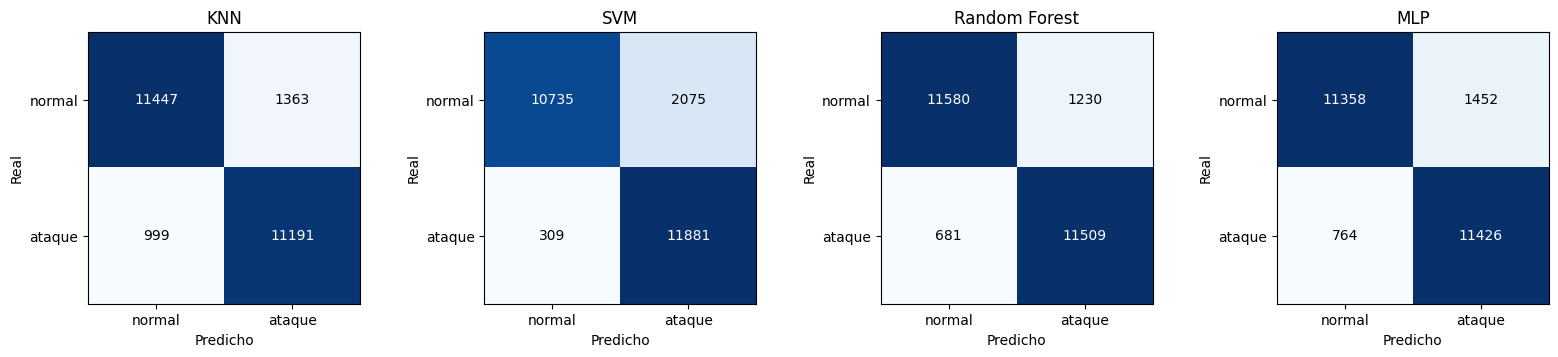

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, nombre in zip(axes, ["KNN", "SVM", "Random Forest", "MLP"]):
    m = resultados[nombre]["matriz_confusion"]
    ax.imshow(m, cmap="Blues")
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, f"{v}", ha="center", va="center", color="white" if v > m.max()/2 else "black")
    ax.set_xticks([0, 1], ["normal", "ataque"]); ax.set_yticks([0, 1], ["normal", "ataque"])
    ax.set_title(nombre); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_matrices_confusion_cv.png", dpi=150); plt.show()

## 5. F1 por pliegue (estabilidad)

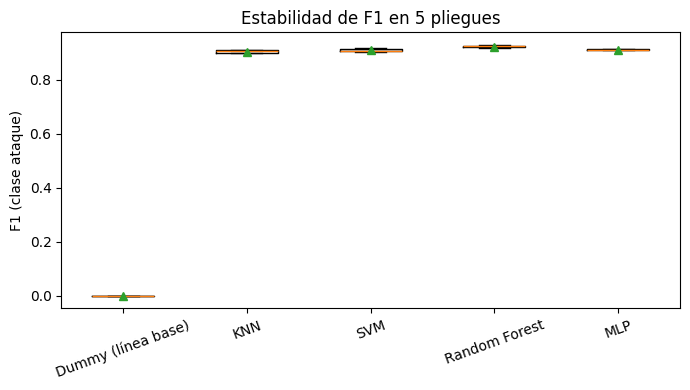

In [7]:
plt.figure(figsize=(7, 4))
plt.boxplot([resultados[n]["folds"]["f1"] for n in modelos], labels=list(modelos), showmeans=True)
plt.ylabel("F1 (clase ataque)"); plt.title("Estabilidad de F1 en 5 pliegues"); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_f1_por_pliegue.png", dpi=150); plt.show()

## 6. Interpretación
- ¿Cuánto mejoran los modelos respecto a la línea base? *(F1 y ROC-AUC del Dummy frente a los demás)*
- ¿Qué modelo tiene mejor **recall de ataque**? En detección de intrusiones, un falso negativo (ataque no detectado) suele costar más que un falso positivo.
- ¿Hay diferencias reales o están dentro de la desviación estándar entre pliegues?
- Costo: tiempo de entrenamiento y de inferencia de cada modelo. ¿Algún modelo es inviable para tráfico en tiempo real?
- **Pasa a la Persona B:** `reports/tabla_resultados_cv.csv`, para integrarla con la versión optimizada por el algoritmo genético.

Todos los modelos superan ampliamente la línea base (F1 = 0 y ROC-AUC = 0,5). Random Forest obtuvo el mejor F1 (0,923 ± 0,005) y ROC-AUC (0,982), con una ventaja mayor que la dispersión entre pliegues, mientras que KNN, SVM y MLP quedaron prácticamente empatados en F1 (0,905–0,912). El SVM alcanzó el mayor recall de ataque (0,975), pero a costa de una menor precisión (0,851) y de la inferencia más lenta (470 ms por 1000 registros). En detección de intrusiones, un falso negativo suele ser más costoso que un falso positivo, por lo que el recall pesa especialmente en la selección final. Estos resultados corresponden a validación cruzada con hiperparámetros iniciales y deben confirmarse en el conjunto de prueba.